# hiNiche: Mouse Brain Visium HD analysis

Multi-scale (spot / cell / niche) cell-type deconvolution and niche discovery on Visium HD mouse brain data.

## 1. Setup and imports

In [21]:
import os
import sys
# cupy (used by rapids_singlecell) compiles GPU kernels at runtime and needs the CUDA headers shipped inside the conda environment
os.environ.setdefault("CUDA_PATH", os.path.join(sys.prefix, "targets", "x86_64-linux"))

# --- Project modules ---
import config
import utils
from train import run_train_seq

# --- Standard library ---
import json
import warnings
from collections import Counter

# --- Data handling ---
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import scipy.sparse as sp
import pyarrow.parquet as pq
import tifffile

# --- Deep learning ---
import torch
import torch.nn.functional as F

# --- Clustering ---
import rapids_singlecell as rsc     # GPU-accelerated neighbors / Leiden / UMAP
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

# --- Plotting ---
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

%load_ext autoreload
%autoreload 2

warnings.filterwarnings("ignore")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Parameter configuration

In [22]:
SAMPLE = "Mousebrain_HD_single_slice"

# Data paths
h5_path              = f"DATA/{SAMPLE}/filtered_feature_bc_matrix.h5"
possition_path       = f"DATA/{SAMPLE}/tissue_positions.parquet"
refile_path          = f"DATA/{SAMPLE}/lambda_matrix.csv"
cell_seg_labels_path = f"DATA/{SAMPLE}/segmentation_mask.npz"
he_image_path        = f"DATA/{SAMPLE}/Visium_HD_Mouse_Brain_Fixed_Frozen_tissue_image.btf"

#Patch save path
PATCH_LOC = f"DATA/{SAMPLE}/mini_batch_cache"

#Model save path
MODEL_SAVE_DIR = f"DATA/{SAMPLE}/checkpoint.pt"

# Cell-type color map defined in config.py
celltype_color= getattr(config, "colormap_mouse_brain_41")
umap_color = getattr(config, "umap_40")
# Model / training hyperparameters
Patch_size  = 512
graph_knn   = 12
niche_knn   = 20
lr          = 0.005
num_epochs  = 30
edge_drop   = 0.5 
member_drop = 0.5
neg_samples = 5
tau         = 1
alpha       = 1
beta        = 2
seed        = 42
device      = "cuda:0"

## 3. Data loading and preprocessing

### 3.1 Load counts, spot positions, and H&E image

In [23]:
# Reference expression profiles (genes x cell types) and nucleus segmentation labels
ref_df = pd.read_csv(refile_path, index_col = 0)
cell_seg_labels = sp.load_npz(cell_seg_labels_path)

# Load counts
adata = sc.read_10x_h5(h5_path)

# Load spot positions
positions = pq.read_table(possition_path).to_pandas()
positions = positions.set_index("barcode")

# Merge positions into obs
adata.obs = adata.obs.join(positions)

# Keep only in-tissue spots (in_tissue == 1)
adata = adata[adata.obs["in_tissue"].fillna(0).astype(int) == 1].copy()
adata = adata[adata.obs["in_tissue"] == 1].copy()

# Load the full-resolution H&E image
with tifffile.TiffFile(he_image_path) as tif:
    series = tif.series[0]
    full_res = series.levels[0].asarray()      # highest resolution level (same as z['0'] before)
    # For a downsampled level: series.levels[2].asarray(), etc.
    # To list levels: print(len(series.levels), [lv.shape for lv in series.levels])


# Grid (array row/col) and full-resolution pixel coordinates
adata.obsm["spatial_grid"]  = adata.obs[["array_row", "array_col"]].to_numpy()
adata.obsm["spatial_pixel"] = adata.obs[["pxl_col_in_fullres", "pxl_row_in_fullres"]].values

### 3.2 Quality control, background filtering, and normalization

In [24]:
# Keep raw counts before normalization
adata.layers["counts"] = adata.X.copy()

adata.var_names_make_unique()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)

# Flag low-count background regions and drop them
adata = utils.background_detector(adata, threshold = 50, n_neighs =4, n_rings = 4)
print(f"[Log] original adata size is {adata.shape}")

before = adata.shape[0]
adata = adata[adata.obs["low_count_region"] < 1]
after = adata.shape[0]
print(f"[Log] filtering background: {before} spots to {after} spots")

# Library-size normalization + log transform
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

[Log] original adata size is (6947755, 19059)
[Log] filtering background: 6947755 spots to 6618476 spots


### 3.3 Align genes with the reference

In [ ]:
# Restrict to genes shared between the data and the reference
overlap_gs = adata.var.index.intersection(ref_df.index)
print(f"[Log] num of gene overlap {len( overlap_gs )}")

adata.obsm["X_mle"] = adata.layers["counts"][:, adata.var_names.isin(overlap_gs)]   # raw counts
adata.obsm["X_input"] = adata[:, adata.var_names.isin(overlap_gs)].X                # normalized model input

print(f"[Log] input gene number is {len(overlap_gs)}")
ref_matrix = ref_df.loc[overlap_gs].values
ref_matrix = np.array(ref_matrix)

celltypes = list(ref_df.columns)
print(f"[Log] rna ref size is {ref_matrix.shape}")

[Log] num of gene overlap 4813
[Log] input gene number is 4813
[Log] rna ref size is (4813, 41)


## 4. Build the spot / cell / niche hierarchy

### 4.1 Spot-to-cell and spot-to-niche assignment

In [26]:
# Spot -> cell assignment from nucleus segmentation
S_s2c_all, cell_background_mask = utils.spot2cell_nuclieseg(adata.obsm["spatial_pixel"], cell_seg_labels, max_spots_per_cell=100, min_spots_per_cell= 3)
print(f"[Log] {S_s2c_all.shape[1]} cells are detected")

# Spot -> niche assignment: each niche is a cell plus its nearest neighbors
S_s2n_all, niche_background_mask, active_niche_indices, S_c2n_all = utils.spot2niche_by_cell_knn(adata.obsm["spatial_grid"], S_s2c_all, k_niche=niche_knn)
background_mask = {"cell": cell_background_mask, "niche":niche_background_mask}

[Log] Active Cells (before filtering): 81607
[Log] Valid Cells (3 <= spots <= 100): 73323
[Log] Filtered Cells (< 3 spots): 8280
[Log] Filtered Cells (> 100 spots): 4
[Log] 73323 cells are detected
[Log] Active Niches: 73323, Cells per Niche (k): 20


### 4.2 Spatial KNN graphs

In [27]:
# Spatial KNN graphs at spot and cell level
spot_edges = utils.build_spot_knn_graph(adata.obsm["spatial_grid"], graph_knn)
cell_edges = utils.build_cell_knn_graph(adata.obsm["spatial_grid"], S_s2c_all, graph_knn)
# Niche graph: reuses the cell KNN graph (one niche per cell), same k as spot/cell graphs
niche_edges = cell_edges

[Log] 79914768 edges generated from 6618476 nodes (k=12)
[Log] 996548 edges generated from 73323 nodes (k=12)


### 4.3 Spatial blocking and subgraph caching

In [28]:
# Split the slide into overlapping spatial blocks (core + halo) for mini-batch training
batch_mask, block_ids = utils.make_block_masks(adata.obsm["spatial_grid"], Patch_size=Patch_size, halo=32, S_s2c=S_s2c_all, S_s2n=S_s2n_all)

# Build and cache per-block subgraph data to disk
utils.build_subgraph_data(adata, ref_matrix, spot_edges, cell_edges, niche_edges,
                          S_s2c_all, S_s2n_all, S_c2n_all, background_mask, batch_mask, block_ids, PATCH_LOC)
print(f"[Log] Original ST is patchfied to {len(block_ids)} blocks with avg {batch_mask['spot_level_core'].sum(dim=1).float().mean().item():.0f} spots, {batch_mask['cell_level_core'].sum(dim=1).float().mean().item():.0f} cells and {batch_mask['niche_level_core'].sum(dim=1).float().mean().item():.0f} niches per block")

[Log] Generating spot masks for 42 blocks...


[Log] Building & saving mini-batches: 100%|██████████| 42/42 [03:25<00:00,  4.89s/it]


[Log] Saved 36 blocks → DATA/Mousebrain_HD_single_slice/mini_batch_cache
[Log] Original ST is patchfied to 42 blocks with avg 157583 spots, 1764 cells and 2029 niches per block


## 5. Model training

In [29]:

emb_all, slice_id = run_train_seq(total_unit_number_per_level = {"spot": S_s2c_all.shape[0], "cell": S_s2c_all.shape[1], "niche": S_s2n_all.shape[1]},
                                  PATCH_LOC = PATCH_LOC,
                                  MODEL_SAVE_DIR = MODEL_SAVE_DIR,
                                  ref_matrix = ref_matrix,
                                  lr = lr,
                                  in_dim = len(overlap_gs),
                                  hidden_dim = len(celltypes),
                                  num_epochs = num_epochs,
                                  edge_drop = edge_drop, 
                                  member_drop = member_drop,
                                  neg_samples = neg_samples,
                                  tau = tau,
                                  alpha = alpha,
                                  beta = beta,
                                  seed = seed,
                                  device = device)

Epoch 30: 100%|██████████| 36/36 [00:06<00:00,  5.42it/s, cl=5.0120, nll=321.3954, entp=-6.5697]


Training finished!
Model saved to DATA/Mousebrain_HD_single_slice/checkpoint.pt


generating embeddings (slice 0)...: 100%|██████████| 36/36 [00:08<00:00,  4.46it/s]


## 6. Re-assign unmapped spots

In [30]:
# Re-assign unmapped (background) spots to nearby cells using spot embeddings
spot_embs = emb_all["spot"].detach().cpu().numpy()
new_assignments = utils.reassign_unmapped_spots(
    S_s2c_all,
    adata.obsm["spatial_grid"],          # grid coordinates, 1 unit = 1 spot
    spot_embs,
    algorithm="fixed_boundary",
    fixed_distance=2,
)

print(f"[Log] {len(new_assignments)} background spots has been re-assigned")

S_s2c_updated = utils.update_S(S_s2c_all, new_assignments)

# Spots that were re-assigned are no longer background
cell_background_mask_updated = []
for i in range(len(cell_background_mask)):
    if i in new_assignments: cell_background_mask_updated.append(False)
    else: cell_background_mask_updated.append(bool(cell_background_mask[i]))

Total unassigned spots: 5724089


Assigning spots (boundary): 100%|██████████| 5724089/5724089 [01:29<00:00, 64215.49it/s]


[Log] 1687786 background spots has been re-assigned


## 7. Visualization

### 7.1 Spot- and cell-level cell-type maps

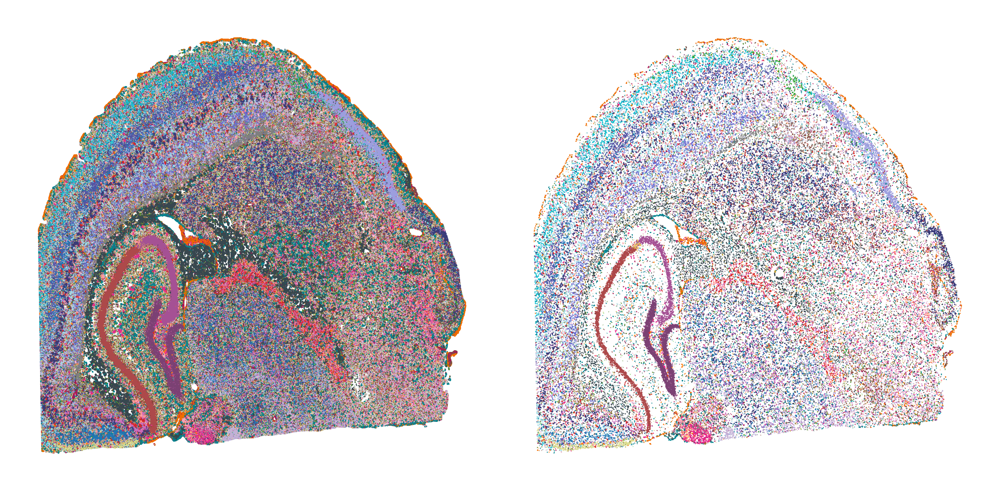

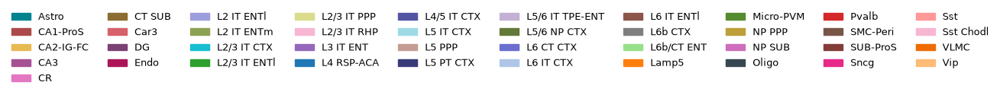

In [31]:
import torch
import torch.nn.functional as F
fig, axes = plt.subplots(1, 2, figsize=(6, 3), dpi=600)  # 1行3列

keys = ["spot", "cell"]
labels_all = {}
for i, ax in enumerate(axes):
    check = keys[i]
    x_raw, y_raw = adata.obsm["spatial_pixel"][:, 0], adata.obsm["spatial_pixel"][:, 1]
    
    # 基础概率
    prob = F.softmax(emb_all[check], dim=1)
    max_prob_raw, max_idx_raw = torch.max(prob, dim=1) 

    if check == "cell":
        # 标准的 Spot -> Cell 映射
        S = S_s2c_updated.coalesce()
        rows, cols = S.indices()[0], S.indices()[1]
        spot2target = torch.full((S.size(0),), -1, dtype=torch.long, device=S.device)
        spot2target[rows] = cols
        max_idx = torch.where(spot2target >= 0, max_idx_raw[spot2target], torch.tensor(-1, device=S.device))
        max_prob = torch.where(spot2target >= 0, max_prob_raw[spot2target], torch.tensor(0.0, device=S.device))
    else:
        max_prob, max_idx = max_prob_raw, max_idx_raw

    # --- 颜色分配逻辑 ---
    cell_labels = []
    for j in range(len(max_prob)):
        # 如果 max_idx 为 -1，说明这个 Spot 不属于任何有效细胞或有效 Niche
        if max_idx[j] == -1:
            cell_labels.append("filtered")
        elif max_prob[j] < 0.1:
            cell_labels.append("ambiguous")
        else:
            cell_labels.append(celltypes[max_idx[j]])
    labels_all[check] = cell_labels
    
    colors = [celltype_color[name] for name in cell_labels]
    ax.scatter(x_raw, y_raw, c=colors, s=0.5, marker='.', linewidths=0)
    ax.invert_yaxis()
    ax.axis("off")

plt.tight_layout()
plt.show()

# 将颜色转换为 legend handles
cell_type = np.asarray(celltypes)[F.softmax(emb_all["spot"], dim=1).argmax(1).cpu().numpy()]
handles = [mpatches.Patch(color=celltype_color.get(c, "#cccccc"), label=c) for c in np.unique(cell_type)]
figL, axL = plt.subplots(figsize=(11, 0.6)); axL.axis("off")
axL.legend(handles=handles, ncol=10, frameon=False, loc="center", fontsize=9)
plt.show()


### 7.2 Niche clustering (UMAP + spatial map)

niche: 22 clusters


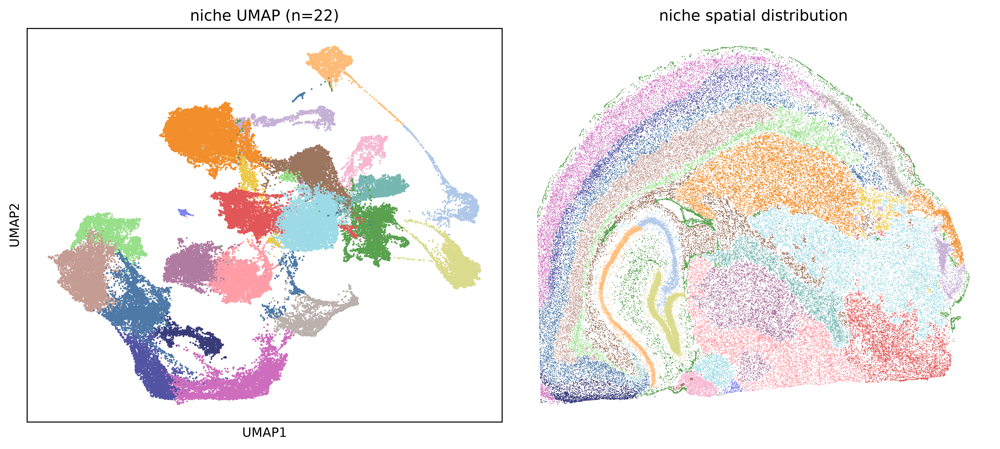

In [32]:
import torch
torch.cuda.empty_cache()

resolution = 0.5   # Leiden resolution; higher -> more clusters
emb_k = 50

# --- 1. Cluster niche embeddings (Leiden) + UMAP, sharing one neighbor graph ---
adata_tmp = ad.AnnData(emb_all["niche"].numpy())
rsc.pp.neighbors(adata_tmp, use_rep='X', n_neighbors=emb_k)
rsc.tl.leiden(adata_tmp, resolution=resolution, random_state=seed)
rsc.tl.umap(adata_tmp, random_state=seed)
niche_label = adata_tmp.obs['leiden'].astype(int).values
niche_umap = adata_tmp.obsm["X_umap"]
clusters_id = {"niche": niche_label}
n_clusters = len(np.unique(niche_label))
print(f"niche: {n_clusters} clusters")

# --- 2. Estimate each cell's position from S_s2c_updated (mean of its spots' coordinates) ---
S = S_s2c_updated.coalesce()
s_rows, c_cols = S.indices()
n_cell = S.size(1)
spatial = torch.as_tensor(adata.obsm["spatial_pixel"], dtype=torch.float32, device=S.device)

cell_pos = torch.zeros((n_cell, 2), device=S.device).index_add_(0, c_cols, spatial[s_rows])
cell_cnt = torch.zeros(n_cell, device=S.device).index_add_(0, c_cols, torch.ones_like(c_cols, dtype=torch.float32))
cell_pos /= cell_cnt.clamp(min=1).unsqueeze(1)

# --- 3. Map niche clusters back to cells ---
cell_niche = torch.full((n_cell,), -1, dtype=torch.long, device=S.device)
active = torch.as_tensor(active_niche_indices, device=S.device).long()
cell_niche[active] = torch.as_tensor(niche_label, device=S.device).long()

keep = (cell_niche >= 0) & (cell_cnt > 0)
pos = cell_pos[keep].cpu().numpy()
ids = cell_niche[keep].cpu().numpy()

# --- 4. Left: niche UMAP; right: niche spatial distribution at cell level (umap_40 colors) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=600)

axes[0].scatter(niche_umap[:, 0], niche_umap[:, 1],
                c=[umap_color[f"Cluster_{v}"] for v in niche_label], s=2, linewidths=0)
axes[0].set_title(f"niche UMAP (n={n_clusters})")
axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_xlabel("UMAP1"); axes[0].set_ylabel("UMAP2")

axes[1].scatter(pos[:, 0], pos[:, 1],
                c=[umap_color[f"Cluster_{v}"] for v in ids], s=2, marker='.', linewidths=0)
axes[1].set_title("niche spatial distribution")
axes[1].invert_yaxis(); axes[1].axis("off")

plt.tight_layout()
plt.show()

### 7.3 Merge niches by cell-type composition

22 niche clusters -> 22 merged


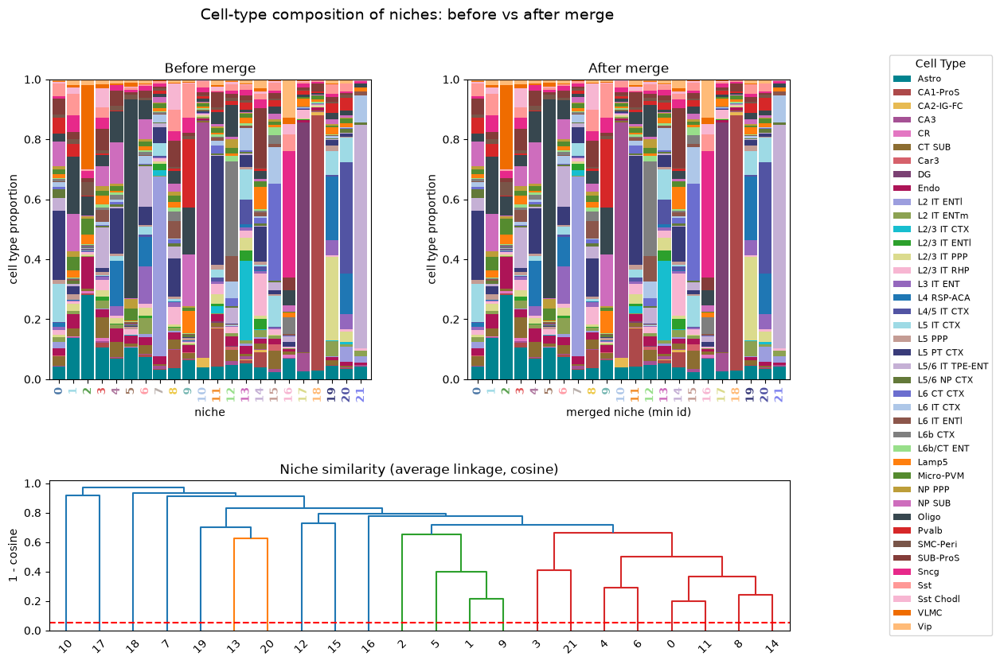

In [33]:
# ---- Cell-type prediction (softmax temperature does not affect argmax, so it is comparable before/after) ----
cell_type = np.asarray(celltypes)[F.softmax(emb_all["cell"], dim=1).argmax(1).cpu().numpy()]

# ---- Composition table (before merge) ----
df_counts = pd.crosstab(np.asarray(clusters_id["niche"]), cell_type)

# ---- Hierarchical clustering + merge ----
comp = df_counts.div(df_counts.sum(1), axis=0)              # row-normalized composition
Z = linkage(comp.values, method="average", metric="cosine")
#Z = linkage(comp.values, method="ward", metric="euclidean")

merge_thresh = 0.05
merged = fcluster(Z, t=merge_thresh, criterion="distance")
group_members = {}
for old, g in zip(comp.index, merged):
    group_members.setdefault(g, []).append(int(old))
old2new = {o: min(members) for members in group_members.values() for o in members}   # smallest id in each group becomes the new label

print(f"{len(comp)} niche clusters -> {len(set(old2new.values()))} merged")
for rep in sorted(set(old2new.values())):
    members = sorted(o for o, r in old2new.items() if r == rep)
    if len(members) > 1:
        print(f"  {members} -> {rep}")

niche_merged = np.array([old2new[l] for l in clusters_id["niche"]])
clusters_id["niche_merged"] = niche_merged

# ---- Composition table (after merge) ----
dfm = pd.crosstab(niche_merged, cell_type)

# ---- Convert to proportions (row-normalized, each bar stacks to 1) ----
comp_before = df_counts.div(df_counts.sum(1), axis=0)      # same as comp
comp_after  = dfm.div(dfm.sum(1), axis=0)

# ================= Layout: top row before/after merge, bottom row full-width dendrogram =================
fig = plt.figure(figsize=(12, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[2, 1], hspace=0.45, wspace=0.3)
ax_before = fig.add_subplot(gs[0, 0])
ax_after  = fig.add_subplot(gs[0, 1])
ax_dendro = fig.add_subplot(gs[1, :])

def stacked(ax, df, title, xlabel):
    """Stacked bar chart of cell-type proportions per niche; x tick labels colored by niche."""
    df.plot(kind="bar", stacked=True, ax=ax,
            color=[celltype_color[c] for c in df.columns], width=0.9, legend=False)
    for tick, nid in zip(ax.get_xticklabels(), df.index):
        tick.set_color(umap_color[f"Cluster_{nid % 40}"]); tick.set_fontweight("bold")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("cell type proportion")
    ax.set_ylim(0, 1)

stacked(ax_before, comp_before, "Before merge", "niche")
stacked(ax_after,  comp_after,  "After merge",  "merged niche (min id)")

# Single legend on the right (the before-merge panel has the most complete set of types)
handles, labels = ax_before.get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(1.0, 0.92), loc="upper left",
           title="Cell Type", prop={"size": 8})

# Bottom row: dendrogram + merge threshold line
dendrogram(Z, labels=comp.index.tolist(), ax=ax_dendro)
ax_dendro.axhline(merge_thresh, ls="--", c="r")
ax_dendro.set_ylabel("1 - cosine")
ax_dendro.set_title("Niche similarity (average linkage, cosine)")

fig.suptitle("Cell-type composition of niches: before vs after merge", fontsize=14)
plt.show()

### 7.4 Niche spatial map before vs. after merge

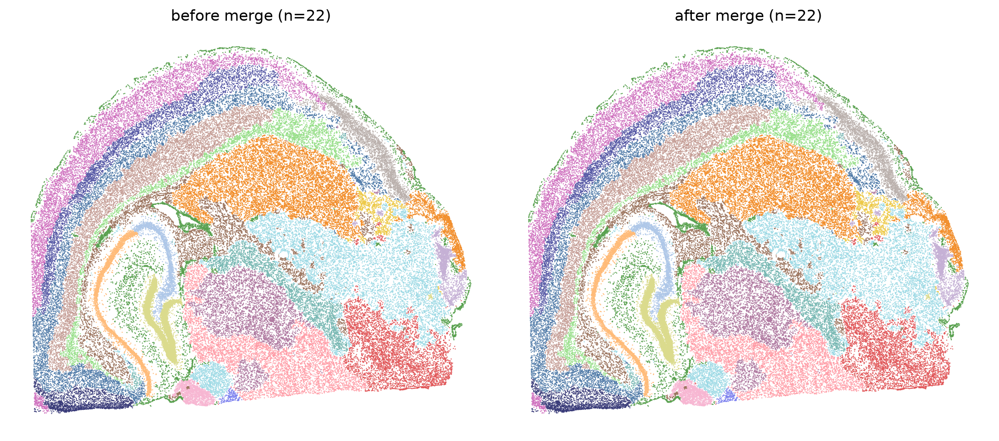

In [34]:
# Merged niche label for each cell (remapped with old2new from the merge step)
ids_merged = np.array([old2new[i] for i in ids])

fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=200)

# Left: before merge
axes[0].scatter(pos[:, 0], pos[:, 1],
                c=[umap_color[f"Cluster_{v % 40}"] for v in ids], s=3, marker='.', linewidths=0)
axes[0].set_title(f"before merge (n={len(np.unique(ids))})")

# Right: after merge
axes[1].scatter(pos[:, 0], pos[:, 1],
                c=[umap_color[f"Cluster_{v % 40}"] for v in ids_merged], s=3, marker='.', linewidths=0)
axes[1].set_title(f"after merge (n={len(np.unique(ids_merged))})")

for a in axes:
    a.invert_yaxis(); a.set_aspect("equal"); a.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# --- Save niche cluster ids (before / after merge) and niche UMAP coordinates ---
# One row per niche (row order = rows of emb_all["niche"])
niche_out = pd.DataFrame({
    "center_cell":        torch.as_tensor(active_niche_indices).cpu().numpy(),   # cell index of the niche center
    "niche_before_merge": np.asarray(clusters_id["niche"]),
    "niche_after_merge":  np.asarray(clusters_id["niche_merged"]),
    "UMAP1":              niche_umap[:, 0],
    "UMAP2":              niche_umap[:, 1],
})
niche_out.index.name = "niche"
niche_out_path = f"DATA/{SAMPLE}/niche_clusters.csv"
niche_out.to_csv(niche_out_path)
print(f"[Log] saved {len(niche_out)} niches -> {niche_out_path}")
niche_out.head()

### 7.5 Cell embedding UMAP and spatial cell-type map

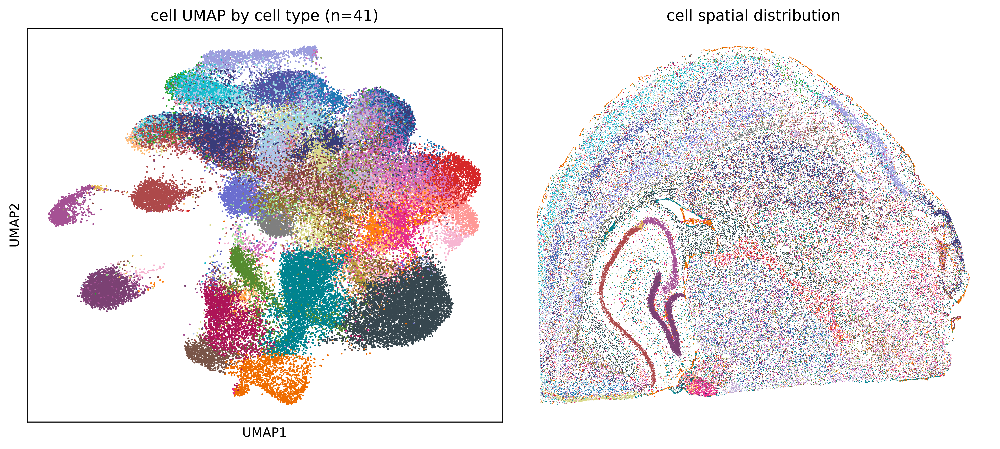

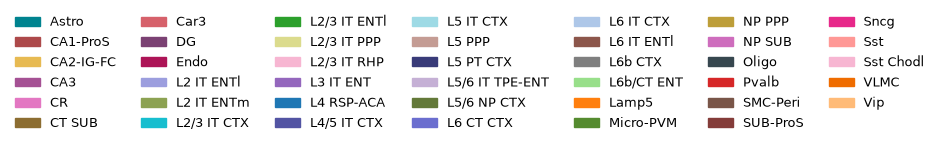

In [35]:
# --- 1. Cell embedding -> UMAP ---
adata_cell = ad.AnnData(emb_all["cell"].numpy())
sc.pp.neighbors(adata_cell, use_rep='X', n_neighbors=emb_k)
sc.tl.umap(adata_cell, random_state=seed)
cell_umap = adata_cell.obsm["X_umap"]

# --- 2. Cell type per cell (argmax) ---
cell_type = np.asarray(celltypes)[F.softmax(emb_all["cell"], dim=1).argmax(1).cpu().numpy()]
col = lambda arr: [celltype_color.get(c, "#cccccc") for c in arr]

# --- 3. Cell coordinates (mean of its spots) ---
S = S_s2c_updated.coalesce()
s_rows, c_cols = S.indices()
n_cell = S.size(1)
spatial = torch.as_tensor(adata.obsm["spatial_pixel"], dtype=torch.float32, device=S.device)
cell_pos = torch.zeros((n_cell, 2), device=S.device).index_add_(0, c_cols, spatial[s_rows])
cell_cnt = torch.zeros(n_cell, device=S.device).index_add_(0, c_cols, torch.ones_like(c_cols, dtype=torch.float32))
cell_pos = (cell_pos / cell_cnt.clamp(min=1).unsqueeze(1)).cpu().numpy()
keep = cell_cnt.cpu().numpy() > 0

# --- 4. Left: cell UMAP colored by type; right: spatial map colored by type ---
fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=600)
axes[0].scatter(cell_umap[:, 0], cell_umap[:, 1], c=col(cell_type), s=2, linewidths=0)
axes[0].set_title(f"cell UMAP by cell type (n={len(np.unique(cell_type))})")
axes[0].set_xticks([]); axes[0].set_yticks([]); axes[0].set_xlabel("UMAP1"); axes[0].set_ylabel("UMAP2")

axes[1].scatter(cell_pos[keep, 0], cell_pos[keep, 1], c=col(cell_type[keep]), s=2, marker='.', linewidths=0)
axes[1].set_title("cell spatial distribution")
axes[1].invert_yaxis(); axes[1].axis("off")
plt.tight_layout(); plt.show()
#plt.savefig("cell_type.png")

# --- Legend ---
handles = [mpatches.Patch(color=celltype_color.get(c, "#cccccc"), label=c) for c in np.unique(cell_type)]
figL, axL = plt.subplots(figsize=(11, 0.6)); axL.axis("off")
axL.legend(handles=handles, ncol=7, frameon=False, loc="center", fontsize=9)
plt.show()

## 8. ROI case studies

### 8.1 Cortex ROI: L5 PT CTX on H&E

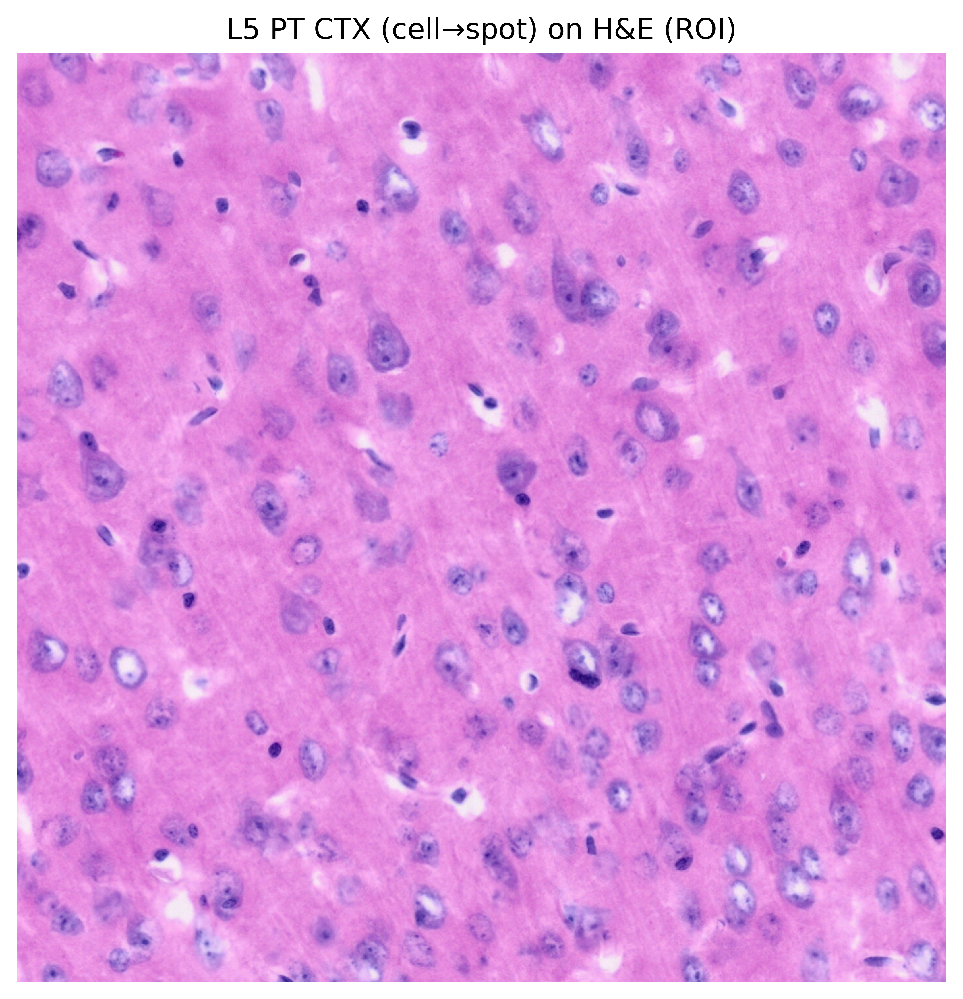

3054 spots (cell type = 'L5 PT CTX') in ROI


In [36]:
target_ct = "L5 PT CTX"

# labels_all["cell"] is already spot-level (each spot = predicted type of its cell), use it directly
spot_ct = np.asarray(labels_all["cell"])

# ---- ROI + filter by target cell type ----
sxy = np.asarray(adata.obsm["spatial_pixel"]); xs, ys = sxy[:, 0], sxy[:, 1]
x_min, x_max, y_min, y_max = 10344-4000+500+1000, 16760-4000+500-1000-1000-1000-1000, 4700-2000+2000, 11116-2000-2000-1000
x_min, x_max, y_min, y_max = int(x_min), int(x_max), int(y_min), int(y_max)
extent = [x_min, x_max, y_min, y_max]
roi = (xs >= x_min) & (xs < x_max) & (ys >= y_min) & (ys < y_max)
m = roi & (spot_ct == target_ct)

col = celltype_color.get(target_ct, "#e6194b") if "celltype_color" in dir() else "#e6194b"

# H&E crop of the ROI
fig, ax = plt.subplots(figsize=(7, 7), dpi=600)
ax.imshow(full_res[y_min:y_max, x_min:x_max], extent=extent, origin="lower", zorder=0)

ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
ax.set_title(f"{target_ct} (cell→spot) on H&E (ROI)")
#plt.savefig("HE.png")
plt.show()
print(f"{m.sum()} spots (cell type = '{target_ct}') in ROI")

### 8.2 Cortex ROI: multi-panel view (cell types, H&E, niches, marker genes)

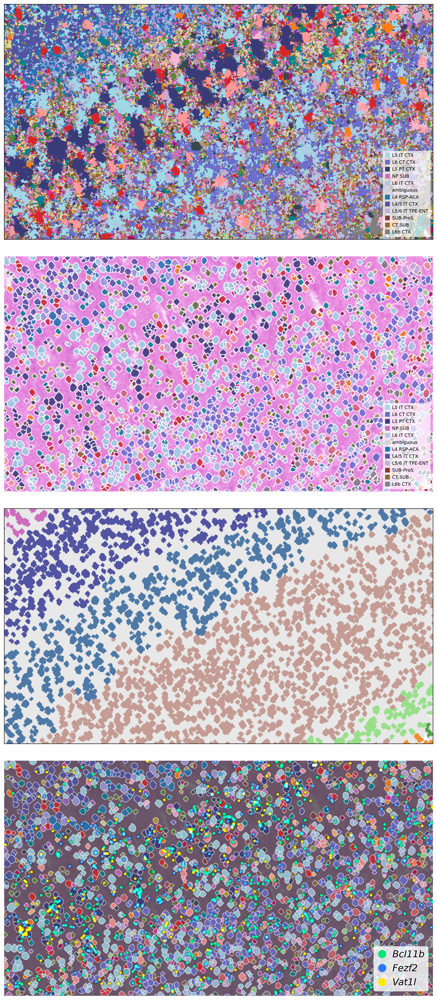

In [37]:
# ============================================================
# 0. ROI / colors / data preparation
# ============================================================
x_min, x_max, y_min, y_max = 10344-4000+500+1000, 16760-4000+500-1000, 4700-2000+1000, 11116-2000-2000-1000
#x_min, y_min, x_max, y_max = 12844 - 500 - 500 -500, 7700-500, 13760 -500 + 500, 8664 + 500 + 500

extent = [x_min, x_max, y_min, y_max]
# Marker genes shown in the pseudo-fluorescence panel
gene_colors = {
    'Bcl11b':  '#00E676',   # green
    'Fezf2':  '#2979FF',   # blue
    'Vat1l':   '#FFEA00',   # yellow
}

xs = adata.obsm['spatial_pixel'][:, 0]
ys = adata.obsm['spatial_pixel'][:, 1]
in_roi = (xs >= x_min) & (xs < x_max) & (ys >= y_min) & (ys < y_max)

spot_cell_types = [celltype_color[ct]
                   for i, ct in enumerate(labels_all["spot"]) if in_roi[i]]

# --- Broadcast niche clusters to spots: spot -> cell -> cell_niche_merged ---
S = S_s2c_updated.coalesce()
srow, scol = S.indices()
n_cell = S.size(1)

# Active niche (cell index) -> niche label
# NOTE: uses clusters_id["niche"] (pre-merge labels), not clusters_id["niche_merged"]
cell_niche_merged = torch.full((n_cell,), -1, dtype=torch.long)
active = torch.as_tensor(active_niche_indices).long()
cell_niche_merged[active] = torch.as_tensor(np.asarray(clusters_id["niche"])).long()

# spot -> its cell -> niche label
spot2cell = torch.full((S.size(0),), -1, dtype=torch.long)
spot2cell[srow] = scol
has_cell = (spot2cell >= 0).numpy()
spot_niche_label = np.full(S.size(0), -1, dtype=int)
spot_niche_label[has_cell] = cell_niche_merged[spot2cell.clamp(min=0)].numpy()[has_cell]

grey = "#e8e8e8"   # spots without a cell
spot_niche_color = np.array([grey] * len(spot_niche_label), dtype=object)
valid = spot_niche_label >= 0
spot_niche_color[valid] = [umap_color[f"Cluster_{v}"] for v in spot_niche_label[valid]]


# ============================================================
# Major cell types: only types with fraction >= MIN_FRAC go into the legend
# ============================================================
MIN_FRAC = 0.0001   # 0.01%
TOP_N    = 12       # upper bound: show at most the top N types

def major_cell_types(label_list, min_frac=MIN_FRAC, top_n=TOP_N):
    """Return the most frequent labels whose fraction >= min_frac (at most top_n)."""
    cnt = Counter(label_list)
    total = sum(cnt.values())
    if total == 0:
        return []
    ranked = sorted(cnt.items(), key=lambda kv: -kv[1])
    keep = [ct for ct, n in ranked if (n / total) >= min_frac]
    return keep[:top_n] if keep else [ct for ct, _ in ranked[:top_n]]


# ============================================================
# Shared legend style
# ============================================================
def _make_legend(ax, handles, labelcolor='black', loc='lower right',
                 frame=True, fontsize=8):
    """Draw a compact legend with a semi-transparent white frame."""
    if not handles:
        return
    leg = ax.legend(handles=handles, loc=loc, fontsize=fontsize,
                    frameon=frame, labelcolor=labelcolor,
                    handlelength=1.0, handletextpad=0.5, borderpad=0.5)
    if frame:
        leg.get_frame().set_facecolor('white')
        leg.get_frame().set_alpha(0.7)
        leg.get_frame().set_edgecolor('none')


# ============================================================
# 4 x 1 figure
# ============================================================
fig, axes = plt.subplots(4, 1, figsize=(24, 24), dpi=300)

# -------- Row 3: niche clusters (spot level, white background, no legend) --------
ax = axes[2]
ax.set_facecolor("white")
ax.scatter(xs[in_roi], ys[in_roi],
           c=spot_niche_color[in_roi], s=4, alpha=1.0, marker="s",
           edgecolors='none', rasterized=True, zorder=2)
ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
axes[2].invert_yaxis()

# -------- Row 1: spot-level cell types (white background + major cell type legend) --------
ax = axes[0]
ax.set_facecolor("white")
ax.scatter(xs[in_roi], ys[in_roi],
           c=spot_cell_types, s=4, alpha=1.0, marker="s",
           edgecolors='none', rasterized=True, zorder=2)
ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
axes[0].invert_yaxis()
spot_ct_in_roi = np.asarray(labels_all["spot"])[in_roi].tolist()
major_p2 = major_cell_types(spot_ct_in_roi)
handles_p2 = [
    Line2D([0], [0], marker='s', linestyle='', markersize=8,
           markerfacecolor=celltype_color[ct], markeredgecolor='none', label=str(ct))
    for ct in major_p2 if ct in celltype_color
]
_make_legend(ax, handles_p2, labelcolor='black')

# -------- Row 2: H&E + cell-level segmentation overlay (+ major cell type legend) --------
ax = axes[1]
ax.imshow(full_res[y_min:y_max, x_min:x_max], extent=extent, origin="lower")
utils.plot_roi_by_xy(ax, x_min, x_max, y_min, y_max,
                     adata, S_s2c_updated, labels_all["cell"], celltype_color,
                     fill_alpha=0.8, contour_lw=1)

ax.set_title("H&E + cells", color='white', fontsize=14, pad=8)

# Only count cells inside the ROI (filtering by cell center coordinates is more accurate)
cell_labels_all = np.asarray(labels_all["cell"]).tolist()
try:
    cell_xy = np.asarray(adata.uns.get("cell_xy", None))
    if cell_xy is not None and len(cell_xy) == len(cell_labels_all):
        in_roi_cell = ((cell_xy[:, 0] >= x_min) & (cell_xy[:, 0] < x_max) &
                       (cell_xy[:, 1] >= y_min) & (cell_xy[:, 1] < y_max))
        cell_labels_roi = [cell_labels_all[i] for i in np.where(in_roi_cell)[0]]
    else:
        cell_labels_roi = cell_labels_all
except Exception:
    cell_labels_roi = cell_labels_all

major_p3 = major_cell_types(cell_labels_roi)
handles_p3 = [
    Line2D([0], [0], marker='o', linestyle='', markersize=8,
           markerfacecolor=celltype_color[ct], markeredgecolor='none', label=str(ct))
    for ct in major_p3 if ct in celltype_color
]
_make_legend(ax, handles_p2, labelcolor='black')   # TODO: probably meant handles_p3

# -------- Row 4: pseudo-fluorescence (marker genes) + cell overlay (keeps gene legend) --------
utils.plot_fluorescent_roi(
    axes[3],
    x_min, x_max, y_min, y_max,
    full_res, adata,
    gene_colors=gene_colors,
    background="dim_he",
    bg_alpha=0.8, bg_brightness=0.30,
    gaussian_sigma=10, blur_intensity=4.0,
    cell_overlay_fn=lambda ax: utils.plot_roi_by_xy(
        ax, x_min, x_max, y_min, y_max,
        adata, S_s2c_updated, labels_all["cell"], celltype_color,
        fill_alpha=0.8, contour_lw=0.5,
    ),
)

# ============================================================
# Save
# ============================================================
plt.tight_layout()
#plt.savefig("Fig_CRC.png", dpi=600, facecolor=fig.get_facecolor())
plt.show()

### 8.3 Hippocampus ROI: CA2-IG-FC on H&E

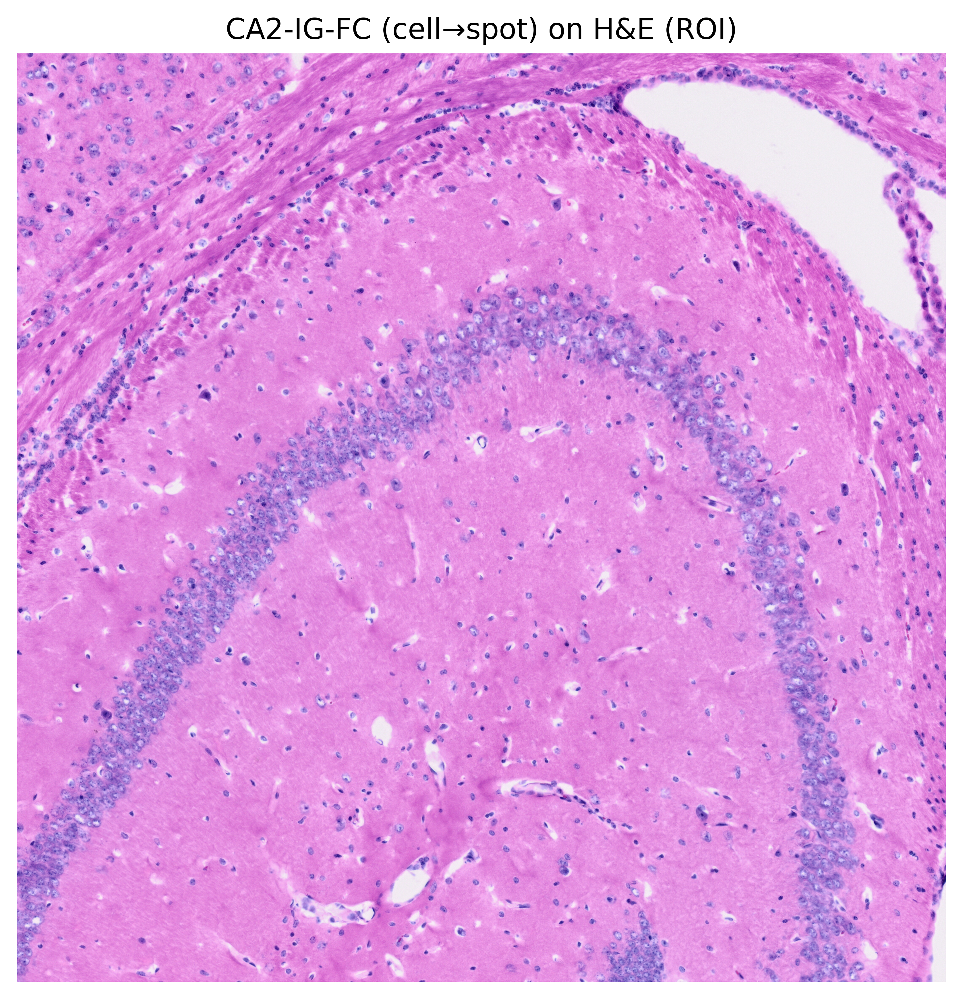

1682 spots (cell type = 'CA2-IG-FC') in ROI


In [38]:
target_ct = "CA2-IG-FC"

# labels_all["cell"] is already spot-level (each spot = predicted type of its cell), use it directly
spot_ct = np.asarray(labels_all["cell"])

# ---- ROI + filter by target cell type ----
sxy = np.asarray(adata.obsm["spatial_pixel"]); xs, ys = sxy[:, 0], sxy[:, 1]
x_min, x_max, y_min, y_max = 10344-4000-1000, 16760-4000-2000-1000, 4700+4000, 11116+2000
x_min, x_max, y_min, y_max = int(x_min), int(x_max), int(y_min), int(y_max)
extent = [x_min, x_max, y_min, y_max]
roi = (xs >= x_min) & (xs < x_max) & (ys >= y_min) & (ys < y_max)
m = roi & (spot_ct == target_ct)

col = celltype_color.get(target_ct, "#e6194b") if "celltype_color" in dir() else "#e6194b"

# H&E crop of the ROI
fig, ax = plt.subplots(figsize=(7, 7), dpi=600)
ax.imshow(full_res[y_min:y_max, x_min:x_max], extent=extent, origin="lower", zorder=0)

ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
ax.set_title(f"{target_ct} (cell→spot) on H&E (ROI)")
plt.show()
print(f"{m.sum()} spots (cell type = '{target_ct}') in ROI")

### 8.4 Hippocampus ROI: multi-panel view (cell types, H&E, niches, marker genes)

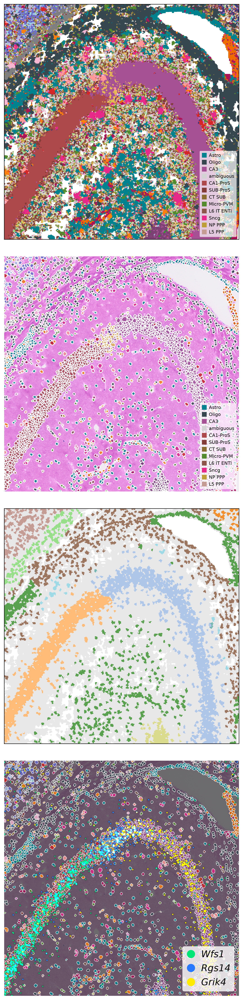

In [39]:
# ============================================================
# 0. ROI / colors / data preparation
# ============================================================
x_min, x_max, y_min, y_max = 10344-4000-1000, 16760-4000-2000-1000, 4700+4000, 11116+2000
#x_min, y_min, x_max, y_max = 12844 - 500 - 500 -500, 7700-500, 13760 -500 + 500, 8664 + 500 + 500

extent = [x_min, x_max, y_min, y_max]
# Marker genes shown in the pseudo-fluorescence panel
gene_colors = {
    'Wfs1':  '#00E676',   # green
    'Rgs14':  '#2979FF',   # blue
    'Grik4':   '#FFEA00',   # yellow
}

xs = adata.obsm['spatial_pixel'][:, 0]
ys = adata.obsm['spatial_pixel'][:, 1]
in_roi = (xs >= x_min) & (xs < x_max) & (ys >= y_min) & (ys < y_max)

spot_cell_types = [celltype_color[ct]
                   for i, ct in enumerate(labels_all["spot"]) if in_roi[i]]

# --- Broadcast niche clusters to spots: spot -> cell -> cell_niche_merged ---
S = S_s2c_updated.coalesce()
srow, scol = S.indices()
n_cell = S.size(1)

# Active niche (cell index) -> niche label
# NOTE: uses clusters_id["niche"] (pre-merge labels), not clusters_id["niche_merged"]
cell_niche_merged = torch.full((n_cell,), -1, dtype=torch.long)
active = torch.as_tensor(active_niche_indices).long()
cell_niche_merged[active] = torch.as_tensor(np.asarray(clusters_id["niche"])).long()

# spot -> its cell -> niche label
spot2cell = torch.full((S.size(0),), -1, dtype=torch.long)
spot2cell[srow] = scol
has_cell = (spot2cell >= 0).numpy()
spot_niche_label = np.full(S.size(0), -1, dtype=int)
spot_niche_label[has_cell] = cell_niche_merged[spot2cell.clamp(min=0)].numpy()[has_cell]

grey = "#e8e8e8"   # spots without a cell
spot_niche_color = np.array([grey] * len(spot_niche_label), dtype=object)
valid = spot_niche_label >= 0
spot_niche_color[valid] = [umap_color[f"Cluster_{v}"] for v in spot_niche_label[valid]]


# ============================================================
# Major cell types: only types with fraction >= MIN_FRAC go into the legend
# ============================================================
MIN_FRAC = 0.0001   # 0.01%
TOP_N    = 12       # upper bound: show at most the top N types

def major_cell_types(label_list, min_frac=MIN_FRAC, top_n=TOP_N):
    """Return the most frequent labels whose fraction >= min_frac (at most top_n)."""
    cnt = Counter(label_list)
    total = sum(cnt.values())
    if total == 0:
        return []
    ranked = sorted(cnt.items(), key=lambda kv: -kv[1])
    keep = [ct for ct, n in ranked if (n / total) >= min_frac]
    return keep[:top_n] if keep else [ct for ct, _ in ranked[:top_n]]


# ============================================================
# Shared legend style
# ============================================================
def _make_legend(ax, handles, labelcolor='black', loc='lower right',
                 frame=True, fontsize=8):
    """Draw a compact legend with a semi-transparent white frame."""
    if not handles:
        return
    leg = ax.legend(handles=handles, loc=loc, fontsize=fontsize,
                    frameon=frame, labelcolor=labelcolor,
                    handlelength=1.0, handletextpad=0.5, borderpad=0.5)
    if frame:
        leg.get_frame().set_facecolor('white')
        leg.get_frame().set_alpha(0.7)
        leg.get_frame().set_edgecolor('none')


# ============================================================
# 4 x 1 figure
# ============================================================
fig, axes = plt.subplots(4, 1, figsize=(24, 24), dpi=300)

# -------- Row 3: niche clusters (spot level, white background, no legend) --------
ax = axes[2]
ax.set_facecolor("white")
ax.scatter(xs[in_roi], ys[in_roi],
           c=spot_niche_color[in_roi], s=4, alpha=1.0, marker="s",
           edgecolors='none', rasterized=True, zorder=2)
ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
axes[2].invert_yaxis()

# -------- Row 1: spot-level cell types (white background + major cell type legend) --------
ax = axes[0]
ax.set_facecolor("white")
ax.scatter(xs[in_roi], ys[in_roi],
           c=spot_cell_types, s=4, alpha=1.0, marker="s",
           edgecolors='none', rasterized=True, zorder=2)
ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
axes[0].invert_yaxis()
spot_ct_in_roi = np.asarray(labels_all["spot"])[in_roi].tolist()
major_p2 = major_cell_types(spot_ct_in_roi)
handles_p2 = [
    Line2D([0], [0], marker='s', linestyle='', markersize=8,
           markerfacecolor=celltype_color[ct], markeredgecolor='none', label=str(ct))
    for ct in major_p2 if ct in celltype_color
]
_make_legend(ax, handles_p2, labelcolor='black')

# -------- Row 2: H&E + cell-level segmentation overlay (+ major cell type legend) --------
ax = axes[1]
ax.imshow(full_res[y_min:y_max, x_min:x_max], extent=extent, origin="lower")
utils.plot_roi_by_xy(ax, x_min, x_max, y_min, y_max,
                     adata, S_s2c_updated, labels_all["cell"], celltype_color,
                     fill_alpha=0.8, contour_lw=1)

ax.set_title("H&E + cells", color='white', fontsize=14, pad=8)

# Only count cells inside the ROI (filtering by cell center coordinates is more accurate)
cell_labels_all = np.asarray(labels_all["cell"]).tolist()
try:
    cell_xy = np.asarray(adata.uns.get("cell_xy", None))
    if cell_xy is not None and len(cell_xy) == len(cell_labels_all):
        in_roi_cell = ((cell_xy[:, 0] >= x_min) & (cell_xy[:, 0] < x_max) &
                       (cell_xy[:, 1] >= y_min) & (cell_xy[:, 1] < y_max))
        cell_labels_roi = [cell_labels_all[i] for i in np.where(in_roi_cell)[0]]
    else:
        cell_labels_roi = cell_labels_all
except Exception:
    cell_labels_roi = cell_labels_all

major_p3 = major_cell_types(cell_labels_roi)
handles_p3 = [
    Line2D([0], [0], marker='o', linestyle='', markersize=8,
           markerfacecolor=celltype_color[ct], markeredgecolor='none', label=str(ct))
    for ct in major_p3 if ct in celltype_color
]
_make_legend(ax, handles_p2, labelcolor='black')   # TODO: probably meant handles_p3

# -------- Row 4: pseudo-fluorescence (marker genes) + cell overlay (keeps gene legend) --------
utils.plot_fluorescent_roi(
    axes[3],
    x_min, x_max, y_min, y_max,
    full_res, adata,
    gene_colors=gene_colors,
    background="dim_he",
    bg_alpha=0.8, bg_brightness=0.30,
    gaussian_sigma=10, blur_intensity=4.0,
    cell_overlay_fn=lambda ax: utils.plot_roi_by_xy(
        ax, x_min, x_max, y_min, y_max,
        adata, S_s2c_updated, labels_all["cell"], celltype_color,
        fill_alpha=0.8, contour_lw=0.5,
    ),
)

# ============================================================
# Save
# ============================================================
plt.tight_layout()
#plt.savefig("Fig_CRC.png", dpi=600, facecolor=fig.get_facecolor())
plt.show()